## Part I — Randomized Sales Data (NumPy)

### 1. Initialize the random seed and generate monthly sales

Use `default_rng(roll_number)` for reproducible results. The upper bound in `integers` is exclusive, so `5001` includes 5,000 in the generated data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROLL_NO = 1024170154
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
CATEGORIES = ["Electronics", "Clothing", "Home & Kitchen", "Sports"]

rng = np.random.default_rng(ROLL_NO)
sales_array = rng.integers(low=1000, high=5001, size=(12, 4))
print(f"Random seed: {ROLL_NO} (even: {ROLL_NO % 2 == 0})")
print("Generated array shape:", sales_array.shape)
print(sales_array)

Random seed: 1024170154 (even: True)
Generated array shape: (12, 4)
[[3242 2182 4549 1245]
 [4518 1702 4589 2350]
 [4970 4310 2629 4569]
 [1316 1115 3938 1886]
 [2623 1048 1556 3444]
 [4653 4444 3119 3837]
 [1727 4555 1566 2359]
 [1489 3729 1157 2442]
 [3410 1537 1269 1724]
 [3960 3956 1174 1997]
 [2694 2919 2255 2675]
 [2017 1024 1526 3417]]


### 2. Convert to a DataFrame and check data quality

The generated sales values are checked for missing values, duplicate rows, and compliance with the required range. No imputation is needed because the values are generated directly.

In [2]:
sales_df = pd.DataFrame(sales_array, index=MONTHS, columns=CATEGORIES)
sales_df.index.name = "Month"

quality_check = pd.Series({
    "Missing values": int(sales_df.isna().sum().sum()),
    "Duplicate rows": int(sales_df.duplicated().sum()),
    "Minimum sales value": int(sales_df.min().min()),
    "Maximum sales value": int(sales_df.max().max()),
    "All values between 1,000 and 5,000": bool(sales_df.ge(1000).all().all() and sales_df.le(5000).all().all()),
}, name="Result")
print("Data quality checks:")
display(quality_check.to_frame())
print("\nMonthly sales DataFrame:")
display(sales_df)

Data quality checks:


,Result
Missing values,0
Duplicate rows,0
Minimum sales value,1024
Maximum sales value,4970
"All values between 1,000 and 5,000",True



Monthly sales DataFrame:


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,3242,2182,4549,1245
Feb,4518,1702,4589,2350
Mar,4970,4310,2629,4569
Apr,1316,1115,3938,1886
May,2623,1048,1556,3444
Jun,4653,4444,3119,3837
Jul,1727,4555,1566,2359
Aug,1489,3729,1157,2442
Sep,3410,1537,1269,1724


## Part II — Data Manipulation and Analysis (Pandas)

### 1. First five rows and summary statistics

In [3]:
print("First five rows:")
display(sales_df.head())
print("Summary statistics by category:")
display(sales_df.describe())

First five rows:


,Electronics,Clothing,Home & Kitchen,Sports
Month,,,,
Jan,3242,2182,4549,1245
Feb,4518,1702,4589,2350
Mar,4970,4310,2629,4569
Apr,1316,1115,3938,1886
May,2623,1048,1556,3444


Summary statistics by category:


,Electronics,Clothing,Home & Kitchen,Sports
count,12.000000,12.000000,12.000000,12.000000
mean,3051.583333,2710.083333,2443.916667,2662.083333
std,1278.334389,1427.807630,1308.771211,970.879588
min,1316.000000,1024.000000,1157.000000,1245.000000
25%,1944.500000,1431.500000,1461.750000,1969.250000
50%,2968.000000,2550.500000,1910.500000,2400.500000
75%,4099.500000,4044.500000,3323.750000,3423.750000
max,4970.000000,4555.000000,4589.000000,4569.000000


### 2. Total sales per category and per month

In [4]:
category_totals = sales_df.sum(axis=0).rename("Total Sales")
month_totals = sales_df.sum(axis=1).rename("Total Sales")
print("Total sales per category:")
display(category_totals.to_frame())
print("Total sales per month:")
display(month_totals.to_frame())

Total sales per category:


,Total Sales
Electronics,36619
Clothing,32521
Home & Kitchen,29327
Sports,31945


Total sales per month:


,Total Sales
Month,
Jan,11218
Feb,13159
Mar,16478
Apr,8255
May,8671
Jun,16053
Jul,10207
Aug,8817
Sep,7940


### 3. Average sales growth between consecutive months

For each category, calculate the month-over-month percentage change and take the arithmetic mean across the 11 transitions. This expresses average growth as a percentage; the first month has no prior month and is excluded.

In [5]:
monthly_category_growth = sales_df.pct_change() * 100
average_category_growth = monthly_category_growth.mean().rename("Average monthly growth (%)")
print("Average month-over-month sales growth by category:")
display(average_category_growth.to_frame().round(2))

Average month-over-month sales growth by category:


,Average monthly growth (%)
Electronics,14.90
Clothing,33.36
Home & Kitchen,3.09
Sports,21.05


### 4. Add Total Sales and Growth Rate

`Growth Rate` is the month-over-month percentage change in the combined monthly sales total. January has no preceding month, so its growth rate is `NaN`.

In [6]:
analysis_df = sales_df.copy()
analysis_df["Total Sales"] = sales_df.sum(axis=1)
analysis_df["Growth Rate"] = analysis_df["Total Sales"].pct_change() * 100
print("Sales data with monthly total and growth rate:")
display(analysis_df.round(2))

Sales data with monthly total and growth rate:


,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate
Month,,,,,,
Jan,3242,2182,4549,1245,11218,NaN
Feb,4518,1702,4589,2350,13159,17.30
Mar,4970,4310,2629,4569,16478,25.22
Apr,1316,1115,3938,1886,8255,-49.90
May,2623,1048,1556,3444,8671,5.04
Jun,4653,4444,3119,3837,16053,85.13
Jul,1727,4555,1566,2359,10207,-36.42
Aug,1489,3729,1157,2442,8817,-13.62
Sep,3410,1537,1269,1724,7940,-9.95


### 5. Apply the roll-number-dependent discount

Roll number **1024170154 is even**, so apply a **10% discount to Electronics**. The original data and original totals are preserved for comparison; the discount simulation is shown in a separate adjusted table.

In [7]:
discounted_df = sales_df.copy()
discounted_df["Electronics"] = discounted_df["Electronics"] * 0.90
discounted_df["Total Sales After Discount"] = discounted_df.sum(axis=1)
discounted_df["Savings on Electronics"] = sales_df["Electronics"] * 0.10
print("Discounted sales (Electronics reduced by 10%):")
display(discounted_df.round(2))

Discounted sales (Electronics reduced by 10%):


,Electronics,Clothing,Home & Kitchen,Sports,Total Sales After Discount,Savings on Electronics
Month,,,,,,
Jan,2917.8,2182,4549,1245,10893.8,324.2
Feb,4066.2,1702,4589,2350,12707.2,451.8
Mar,4473.0,4310,2629,4569,15981.0,497.0
Apr,1184.4,1115,3938,1886,8123.4,131.6
May,2360.7,1048,1556,3444,8408.7,262.3
Jun,4187.7,4444,3119,3837,15587.7,465.3
Jul,1554.3,4555,1566,2359,10034.3,172.7
Aug,1340.1,3729,1157,2442,8668.1,148.9
Sep,3069.0,1537,1269,1724,7599.0,341.0


## Part III — Visualizations (Matplotlib and Seaborn)

### 1. Monthly sales trends for each product category

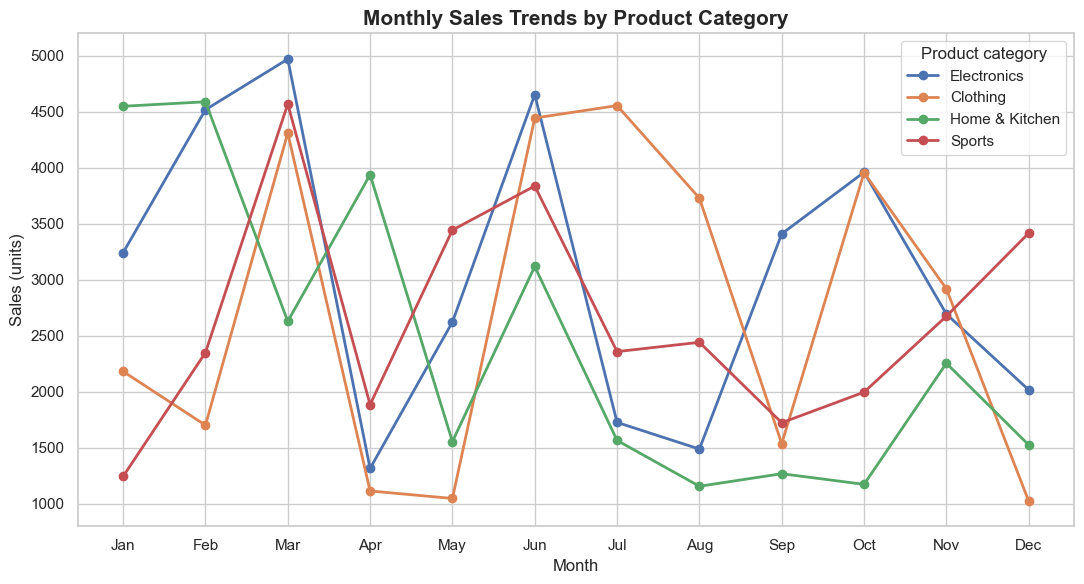

In [8]:
sns.set_theme(style="whitegrid", context="notebook")
fig, ax = plt.subplots(figsize=(11, 6))
for category in CATEGORIES:
    ax.plot(MONTHS, sales_df[category], marker="o", linewidth=2, label=category)
ax.set_title("Monthly Sales Trends by Product Category", fontsize=15, weight="bold")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (units)")
ax.legend(title="Product category", frameon=True)
ax.set_ylim(800, 5200)
fig.tight_layout()
fig.savefig("Assignment7_monthly_sales_trends.png", dpi=160, bbox_inches="tight")
plt.show()

### 2. Sales distribution by category (box plots)

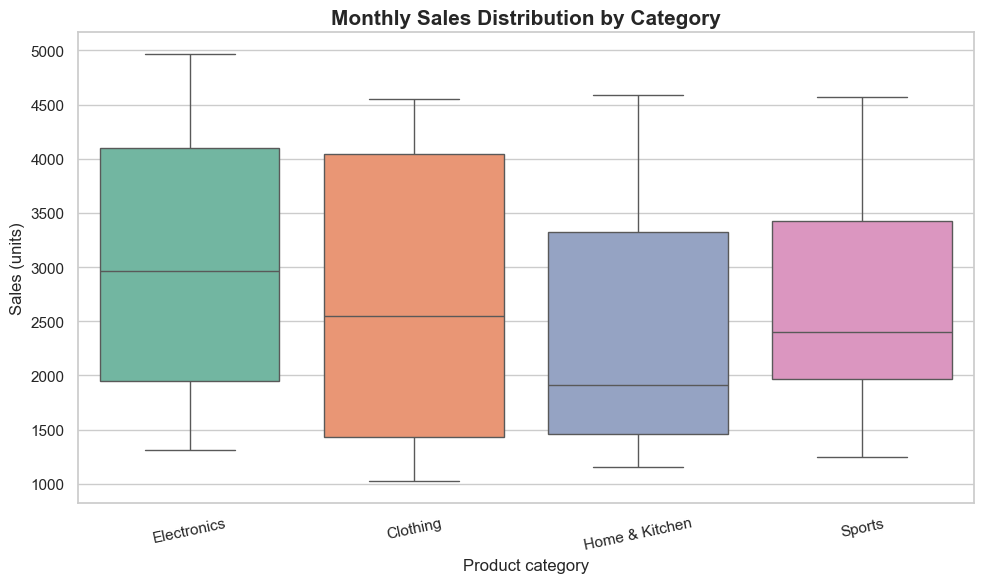

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
long_sales = sales_df.reset_index().melt(id_vars="Month", var_name="Category", value_name="Sales")
sns.boxplot(data=long_sales, x="Category", y="Sales", hue="Category", palette="Set2", legend=False, ax=ax)
ax.set_title("Monthly Sales Distribution by Category", fontsize=15, weight="bold")
ax.set_xlabel("Product category")
ax.set_ylabel("Sales (units)")
ax.tick_params(axis="x", rotation=12)
fig.tight_layout()
fig.savefig("Assignment7_sales_boxplots.png", dpi=160, bbox_inches="tight")
plt.show()

## Q2 — NumPy array operations

Given `[[1, -2, 3], [-4, 5, -6]]`, calculate absolute values; the 25th, 50th, and 75th percentiles for the flattened array, each column, and each row; and mean, median, and population standard deviation (`ddof=0`) for the same groupings.

In [10]:
array = np.array([[1, -2, 3], [-4, 5, -6]])
print("Original array:")
print(array)
print("\nElement-wise absolute value:")
print(np.abs(array))

percentiles = [25, 50, 75]
percentile_results = {
    "Flattened array": np.percentile(array, percentiles),
    "Each column (axis=0)": np.percentile(array, percentiles, axis=0),
    "Each row (axis=1)": np.percentile(array, percentiles, axis=1),
}
print("\n25th, 50th, and 75th percentiles:")
for label, values in percentile_results.items():
    print(f"{label}:\n{values}")

stat_rows = []
for label, values in [
    ("Flattened array", array.ravel()),
    ("Each column", array),
    ("Each row", array),
]:
    axis = None if label == "Flattened array" else (0 if label == "Each column" else 1)
    stat_rows.append((label, np.mean(values, axis=axis), np.median(values, axis=axis), np.std(values, axis=axis)))
print("\nMean, median, and standard deviation:")
for label, mean, median, std in stat_rows:
    print(f"{label}: mean={mean}, median={median}, std={std}")

Original array:
[[ 1 -2  3]
 [-4  5 -6]]

Element-wise absolute value:
[[1 2 3]
 [4 5 6]]

25th, 50th, and 75th percentiles:
Flattened array:
[-3.5 -0.5  2.5]
Each column (axis=0):
[[-2.75 -0.25 -3.75]
 [-1.5   1.5  -1.5 ]
 [-0.25  3.25  0.75]]
Each row (axis=1):
[[-0.5 -5. ]
 [ 1.  -4. ]
 [ 2.   0.5]]

Mean, median, and standard deviation:
Flattened array: mean=-0.5, median=-0.5, std=3.8622100754188224
Each column: mean=[-1.5  1.5 -1.5], median=[-1.5  1.5 -1.5], std=[2.5 3.5 4.5]
Each row: mean=[ 0.66666667 -1.66666667], median=[ 1. -4.], std=[2.05480467 4.78423336]


## Q3 — Floor, ceiling, truncation, and rounding

`np.round` uses ties-to-even for exact half values (for example, `0.5 → 0` and `-0.5 → -0.0`).

In [11]:
a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])
rounding_results = pd.DataFrame({
    "Value": a,
    "Floor": np.floor(a),
    "Ceiling": np.ceil(a),
    "Truncated": np.trunc(a),
    "Rounded (nearest integer)": np.round(a),
})
print("Floor, ceiling, truncated, and rounded values:")
display(rounding_results)

Floor, ceiling, truncated, and rounded values:


,Value,Floor,Ceiling,Truncated,Rounded (nearest integer)
0,-1.8,-2.0,-1.0,-1.0,-2.0
1,-1.6,-2.0,-1.0,-1.0,-2.0
2,-0.5,-1.0,-0.0,-0.0,-0.0
3,0.5,0.0,1.0,0.0,0.0
4,1.6,1.0,2.0,1.0,2.0
5,1.8,1.0,2.0,1.0,2.0
6,3.0,3.0,3.0,3.0,3.0


## Q4 — Swap two elements in a list using a temporary variable

In [12]:
def swap_list_elements(items, first_index, second_index):
    """Swap two list elements in place using a temporary variable."""
    if not (0 <= first_index < len(items) and 0 <= second_index < len(items)):
        raise IndexError("Both indices must refer to existing list positions.")
    temporary = items[first_index]
    items[first_index] = items[second_index]
    items[second_index] = temporary
    return items

example_list = ["Electronics", "Clothing", "Sports", "Books"]
print("Before swap:", example_list)
swap_list_elements(example_list, 0, 2)
print("After swapping positions 0 and 2:", example_list)

Before swap: ['Electronics', 'Clothing', 'Sports', 'Books']
After swapping positions 0 and 2: ['Sports', 'Clothing', 'Electronics', 'Books']


## Q5 — Swap two set elements by converting the set to a list first

A set is unordered, so it has no stable positions to swap. For a repeatable demonstration, convert a set to a **sorted list**, swap two list positions, and convert it back. The intermediate list shows the swapped order, but converting back to a set discards that order; the set's members are unchanged.

In [13]:
def swap_set_elements_via_list(values, first_index, second_index):
    """Sort a set into a list, swap two positions, then return the list and set."""
    items = sorted(values)
    if not (0 <= first_index < len(items) and 0 <= second_index < len(items)):
        raise IndexError("Both indices must refer to existing list positions.")
    temporary = items[first_index]
    items[first_index] = items[second_index]
    items[second_index] = temporary
    return items, set(items)

example_set = {10, 20, 30, 40}
print("Original set:", example_set)
swapped_list, result_set = swap_set_elements_via_list(example_set, 0, 1)
print("List after swapping positions 0 and 1:", swapped_list)
print("Set after converting the swapped list back:", result_set)
print("Same members as original set:", result_set == example_set)

Original set: {40, 10, 20, 30}
List after swapping positions 0 and 1: [20, 10, 30, 40]
Set after converting the swapped list back: {40, 10, 20, 30}
Same members as original set: True


## Conclusion

The notebook generated reproducible monthly data using the student's roll number, validated and summarized the data, measured growth, demonstrated the required even-roll-number discount, visualized monthly trends and category distributions, and completed each NumPy and Python programming exercise.